# Exploración 3: pronóstico a 3 y 6 meses

Un mes de anticipación es poco para planificar transporte, almacenamiento o ventas. En esta notebook extendemos el pronóstico a **3 meses** (octubre 2026) y **6 meses** (enero 2027).

El total de un mes futuro tiene dos partes:

1. **Pozos que ya producían en julio**: entrenamos el mismo Random Forest, pero con un objetivo distinto, la producción del pozo 3 o 6 meses después del mes de corte.
2. **Pozos que se conecten después de julio**: cantidad esperada de pozos por mes × curva tipo de un pozo nuevo (exploración 1). A 3 y 6 meses esta parte deja de ser chica.

Primero medimos qué tan bien funciona cada parte con un pronóstico rodante, y después pronosticamos octubre y enero.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comun import *

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.float_format", lambda valor: f"{valor:,.1f}")
plt.rcParams["figure.figsize"] = (11, 4.5)

In [2]:
panel, inferencia = cargar_panel()
produccion = cargar_produccion_pais()
resumen = resumen_pozos_nuevos(produccion)

for horizonte in (1, 3, 6):
    datos = agregar_objetivo_horizonte(panel, horizonte)
    print(f"Horizonte {horizonte}: {len(datos):,} filas con objetivo conocido")

Horizonte 1: 415,126 filas con objetivo conocido
Horizonte 3: 403,995 filas con objetivo conocido


Horizonte 6: 389,019 filas con objetivo conocido


## 1. Pronóstico rodante a 3 y 6 meses

Para cada mes objetivo entre octubre de 2025 y julio de 2026 nos paramos en el mes de corte (3 o 6 meses antes), entrenamos con los 24 meses de objetivos conocidos hasta ese corte y pronosticamos. Para los pozos nuevos usamos la cantidad media de pozos de los 12 meses anteriores al corte y la curva tipo calculada con información hasta el corte.

La persistencia (suponer que el total no cambia) sigue siendo la referencia.

Esta celda entrena 20 modelos y tarda alrededor de media hora.

In [3]:
meses_objetivo = pd.date_range("2025-10-01", "2026-07-01", freq="MS")
resultados = []
for horizonte in (3, 6):
    rodante = backtest_rodante(panel, horizonte=horizonte, meses_objetivo=meses_objetivo)
    rodante["nuevos_pronostico_m3"] = [
        pronostico_pozos_nuevos(produccion, resumen, corte, horizonte=horizonte)[0] for corte in rodante["mes_corte"]
    ]
    rodante["nuevos_real_m3"] = [
        petroleo_conectados_despues(produccion, corte, objetivo)
        for corte, objetivo in zip(rodante["mes_corte"], rodante["mes_objetivo"])
    ]
    resultados.append(rodante)

rodante = pd.concat(resultados, ignore_index=True)
rodante["total_real_m3"] = resumen.loc[rodante["mes_objetivo"], "total_pais_m3"].to_numpy()
rodante["total_mes_corte_m3"] = resumen.loc[rodante["mes_corte"], "total_pais_m3"].to_numpy()
rodante["total_pronostico_m3"] = rodante["pronostico_existentes_m3"] + rodante["nuevos_pronostico_m3"]

rodante["error_existentes_%"] = (rodante["pronostico_existentes_m3"] / rodante["real_existentes_m3"] - 1) * 100
rodante["error_nuevos_%"] = (rodante["nuevos_pronostico_m3"] / rodante["nuevos_real_m3"] - 1) * 100
rodante["error_total_%"] = (rodante["total_pronostico_m3"] / rodante["total_real_m3"] - 1) * 100
rodante["error_persistencia_%"] = (rodante["total_mes_corte_m3"] / rodante["total_real_m3"] - 1) * 100
rodante["acierta_direccion"] = (
    np.sign(rodante["total_pronostico_m3"] - rodante["total_mes_corte_m3"])
    == np.sign(rodante["total_real_m3"] - rodante["total_mes_corte_m3"])
)
rodante.to_csv(RUTA_RESULTADOS / "backtest_rodante_3_6_meses.csv", index=False)

display(rodante[["horizonte", "mes_corte", "mes_objetivo", "total_real_m3", "total_pronostico_m3",
                 "error_existentes_%", "error_nuevos_%", "error_total_%", "error_persistencia_%"]])

Usando resultados guardados: rodante_h3_202510_202607_v24.csv


Usando resultados guardados: rodante_h6_202510_202607_v24.csv


,horizonte,mes_corte,mes_objetivo,total_real_m3,total_pronostico_m3,error_existentes_%,error_nuevos_%,error_total_%,error_persistencia_%
0,3,2025-07-01,2025-10-01,"2,822,493.7","2,634,519.2",-4.0,-23.4,-6.7,-10.3
1,3,2025-08-01,2025-11-01,"2,771,640.3","2,800,773.2",1.1,1.0,1.1,-5.5
2,3,2025-09-01,2025-12-01,"2,930,406.2","2,817,978.1",-3.1,-9.6,-3.8,-10.2
3,3,2025-10-01,2026-01-01,"2,974,829.4","2,916,283.1",-3.2,8.9,-2.0,-5.1
4,3,2025-11-01,2026-02-01,"2,647,858.8","2,855,432.0",5.7,30.4,7.8,4.7
5,3,2025-12-01,2026-03-01,"2,964,370.0","2,916,210.4",-2.3,4.7,-1.6,-1.1
6,3,2026-01-01,2026-04-01,"2,956,329.5","2,939,960.9",-0.9,2.7,-0.6,0.6
7,3,2026-02-01,2026-05-01,"3,088,334.2","2,896,007.3",-5.2,-14.3,-6.2,-14.3
8,3,2026-03-01,2026-06-01,"3,041,399.8","2,988,400.5",1.4,-22.5,-1.7,-2.5
9,3,2026-04-01,2026-07-01,"3,198,190.3","3,124,058.1",1.0,-23.1,-2.3,-7.6


## 2. Resumen por horizonte

Agregamos el horizonte de 1 mes de la exploración 2 si ya fue ejecutada.

In [4]:
ruta_1_mes = RUTA_RESULTADOS / "backtest_rodante_1_mes.csv"
todos = rodante.copy()
if ruta_1_mes.exists():
    un_mes = pd.read_csv(ruta_1_mes, parse_dates=["mes_corte", "mes_objetivo"])
    todos = pd.concat([un_mes, rodante], ignore_index=True)

resumen_horizontes = todos.groupby("horizonte").agg(
    meses_evaluados=("mes_objetivo", "size"),
    mae_pozo_modelo=("mae_modelo", "mean"),
    mae_pozo_persistencia=("mae_persistencia", "mean"),
    error_existentes_abs=("error_existentes_%", lambda e: e.abs().mean()),
    error_total_abs=("error_total_%", lambda e: e.abs().mean()),
    sesgo_total=("error_total_%", "mean"),
    error_persistencia_abs=("error_persistencia_%", lambda e: e.abs().mean()),
    aciertos_direccion=("acierta_direccion", "sum"),
)
if "error_nuevos_%" in todos:
    resumen_horizontes["sesgo_pozos_nuevos"] = todos.groupby("horizonte")["error_nuevos_%"].mean()
display(resumen_horizontes)
resumen_horizontes.to_csv(RUTA_RESULTADOS / "resumen_por_horizonte.csv")

,meses_evaluados,mae_pozo_modelo,mae_pozo_persistencia,error_existentes_abs,error_total_abs,sesgo_total,error_persistencia_abs,aciertos_direccion,sesgo_pozos_nuevos
horizonte,,,,,,,,,
1,19,122.7,155.5,2.9,3.0,-0.2,5.1,16,NaN
3,10,185.4,271.2,2.8,3.4,-1.6,6.2,8,-4.5
6,10,189.7,306.1,2.7,4.8,-2.7,11.8,10,-5.6


## 3. Pronóstico de octubre 2026 y enero 2027

Entrenamos con los 24 meses de objetivos que terminan en julio de 2026 y pronosticamos los pozos que producían en julio. Sumamos el aporte esperado de los pozos que se conecten después de julio. El rango del 80 % sale de los percentiles 10 y 90 de los errores del pronóstico rodante de cada horizonte.

In [5]:
total_julio = resumen.loc["2026-07-01", "total_pais_m3"]
filas = []
pronosticos_pozo = []
for horizonte in (1, 3, 6):
    pozos, _ = pronostico_desde_julio(panel, inferencia, horizonte)
    pronosticos_pozo.append(pozos.assign(horizonte=horizonte))
    existentes = pozos["produccion_predicha_m3"].sum()
    nuevos, pozos_por_mes = pronostico_pozos_nuevos(produccion, resumen, "2026-07-01", horizonte)
    central = existentes + nuevos
    errores = todos.loc[todos["horizonte"] == horizonte, "error_total_%"] / 100
    filas.append({
        "horizonte": horizonte,
        "mes": pozos["mes_objetivo"].iloc[0],
        "pozos_existentes_m3": existentes,
        "pozos_nuevos_m3": nuevos,
        "total_m3": central,
        "bajo_P10_m3": central / (1 + errores.quantile(0.90)) if len(errores) else np.nan,
        "alto_P90_m3": central / (1 + errores.quantile(0.10)) if len(errores) else np.nan,
    })

pronostico = pd.DataFrame(filas).set_index("horizonte")
for columna in ["pozos_existentes_m3", "total_m3", "bajo_P10_m3", "alto_P90_m3"]:
    pronostico[columna.replace("_m3", "_vs_julio_%")] = (pronostico[columna] / total_julio - 1) * 100
display(pronostico)

pronostico.to_csv(RUTA_RESULTADOS / "pronostico_3_6_meses.csv")
pd.concat(pronosticos_pozo).to_csv(RUTA_RESULTADOS / "pronostico_por_pozo_1_3_6_meses.csv", index=False)

,mes,pozos_existentes_m3,pozos_nuevos_m3,total_m3,bajo_P10_m3,alto_P90_m3,pozos_existentes_vs_julio_%,total_vs_julio_%,bajo_P10_vs_julio_%,alto_P90_vs_julio_%
horizonte,,,,,,,,,,
1,2026-08-01,"3,235,485.8","32,726.0","3,268,211.8","3,103,120.8","3,380,659.8",1.2,2.2,-3.0,5.7
3,2026-10-01,"3,103,883.9","427,872.9","3,531,756.8","3,471,699.0","3,768,041.7",-2.9,10.4,8.6,17.8
6,2027-01-01,"2,690,865.9","1,098,104.1","3,788,970.0","3,709,522.1","4,066,412.6",-15.9,18.5,16.0,27.1


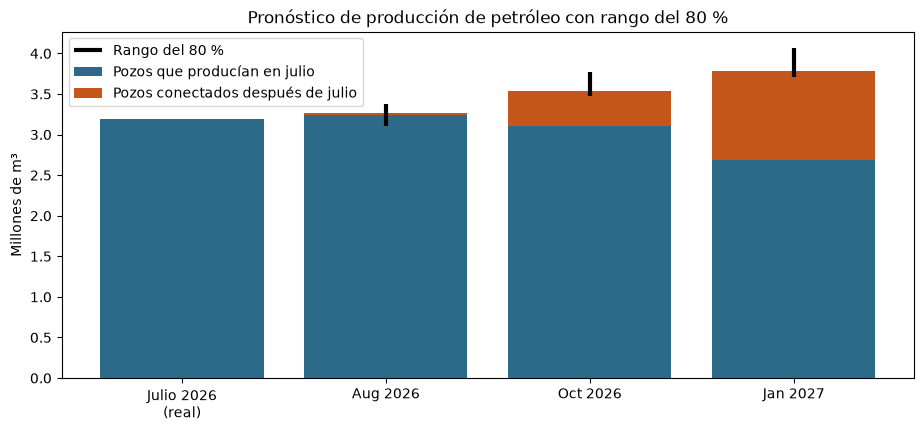

In [6]:
fig, eje = plt.subplots()
etiquetas = ["Julio 2026\n(real)"] + [f"{m:%b %Y}" for m in pronostico["mes"]]
existentes = [total_julio] + list(pronostico["pozos_existentes_m3"])
nuevos = [0] + list(pronostico["pozos_nuevos_m3"])
eje.bar(etiquetas, np.array(existentes) / 1e6, color="#2D6A8A", label="Pozos que producían en julio")
eje.bar(etiquetas, np.array(nuevos) / 1e6, bottom=np.array(existentes) / 1e6, color="#C4561B",
        label="Pozos conectados después de julio")
eje.vlines(etiquetas[1:], pronostico["bajo_P10_m3"] / 1e6, pronostico["alto_P90_m3"] / 1e6,
           color="black", linewidth=3, label="Rango del 80 %")
eje.set_ylabel("Millones de m³")
eje.set_title("Pronóstico de producción de petróleo con rango del 80 %")
eje.legend()
plt.show()

## Conclusiones

- **El modelo de pozos existentes funciona igual de bien a 3 y 6 meses**: su error en el total es de 2,8 % y 2,7 %, parecido al de 1 mes. Por pozo, el error medio es de 185 a 190 m³, contra 270 a 306 m³ de la persistencia.
- **La incertidumbre crece con los pozos nuevos.** Con la variante elegida en la exploración 1, el error del total es de 3,4 % a 3 meses y 4,8 % a 6 meses, contra 6,2 % y 11,8 % de la persistencia. Todavía queda un sesgo hacia abajo (−1,6 % y −2,7 %), que el rango tiene en cuenta.
- **Sin pozos nuevos la producción cae**: los pozos que producían en julio bajarían 2,9 % hasta octubre y 15,9 % hasta enero.
- **Con el ritmo actual de unos 49 pozos nuevos por mes:**
  - octubre 2026: 3,53 millones de m³ (+10 % respecto de julio), rango del 80 % entre 3,47 y 3,77 millones;
  - enero 2027: 3,79 millones de m³ (+18 % respecto de julio), rango del 80 % entre 3,71 y 4,07 millones.
- **Supuesto clave:** el pronóstico supone que el ritmo de conexión de pozos se mantiene. El rango refleja los errores históricos del método, no un escenario de menor actividad. Si se conectan menos pozos, el resultado puede quedar por debajo del rango.